In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [4]:
loan = pd.read_csv(r"F:\MACHINE LEARNING\SOMETHING\Datasets\vidya_loan_train.csv", index_col=0)
loan.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [6]:
X,y = loan.drop('Loan_Status',axis=1),loan.Loan_Status
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=26)


In [12]:
y.value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

In [21]:
ohe=OneHotEncoder(sparse_output=False,drop='first').set_output(transform='pandas')
imp_cat=SimpleImputer(strategy='most_frequent')
imp_cat=imp_cat.set_output(transform='pandas')
imp_num=SimpleImputer(strategy='mean')
imp_num=imp_num.set_output(transform='pandas')
ct=make_column_transformer((imp_cat,make_column_selector(dtype_include=object)),(imp_num,make_column_selector(dtype_exclude=object)),verbose_feature_names_out=False)
ct_imp=ct.set_output(transform='pandas')
ct_ohe = make_column_transformer((ohe,make_column_selector(dtype_include=object)),
                                 ('passthrough',make_column_selector(dtype_exclude=object)),verbose_feature_names_out=False).set_output(transform='pandas')
sc=StandardScaler().set_output(transform='pandas')

In [22]:
ks=[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16]
scores=[]
for k in ks:
    knn=KNeighborsClassifier(n_neighbors=k)
    pipe=Pipeline([('ct_imp',ct_imp),('ct_ohe',ct_ohe),('sc',sc),('knn',knn)])         
    pipe.fit(X_train,y_train)
    pred=pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,pred)])
df_score=pd.DataFrame(scores,columns=['K','scores'])
df_score.sort_values('scores',ascending=False,ignore_index=True)

,K,scores
0,14,0.832432
1,16,0.832432
2,11,0.827027
3,12,0.827027
4,15,0.827027
5,13,0.821622
6,10,0.821622
7,9,0.821622
8,7,0.805405
9,5,0.783784


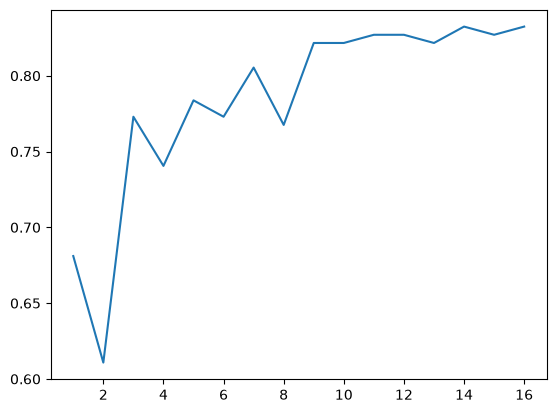

In [25]:
import matplotlib.pyplot as plt
plt.plot(df_score.K,df_score.scores)
plt.show()